In [1]:
import os
import sys

sys.path.append(os.path.abspath(os.path.join(os.path.dirname(os.getcwd()))))
sys.path.append(os.path.abspath(os.path.join("..", "src")))

In [ ]:
import torch
import numpy as np 
import sympy as sp
import matplotlib.pyplot as plt

from mpl_toolkits.mplot3d import Axes3D
from tutorials.utils import matplotlib_defaults as mpl_defaults

# mpl_defaults.apply()

In [3]:
from tensopsciml import TensOps
from tensopsciml import MetrOps, VolFormOps, ConnectOps, Derivative

## The `TensOps` wrapper

This tutorial walks through the core ideas behind `TensOps`, the tensor-aware wrapper that powers the examples in this repository, in order to progressively build intuition about how metadata such as domain, codomain, and index configuration are carried alongside raw tensor values so that downstream calculus operations remain consistent.

The `TensOps` class encapsulates a backend tensor (currently implemented exclusively in `PyTorch`) together with rich tensor-calculus metadata. It keeps track of the tensor's spatial domain, codomain dimensions, and index configuration (contravariance, covariance, and their index order) so that downstream operations can validate shapes and index positions consistently.

**Required arguments**

- `data`: Backend tensor following the shape convention ``[N_samples, codomain..., discretization...]`` $^1$.
- `domain_dim`: Number of domain (discretization) dimensions.
- `codomain_dim`: List describing the shape of the tensor.
- `order`: Two-element list `[contravariant_order, covariant_order]` that states how many upper and lower indices the tensor owns.
- `contravariant_indices`: Positions of contravariant (upper) indices.
- `covariant_indices`: Positions of covariant (lower) indices.

Internally, the class validates shapes, index positions, and tensorial order to ensure the numerical data matches these mathematical descriptors.

$^1$ The next examples particularize this convention so that the shape structure becomes tangible.

## Examples

In this section, we will construct several examples for different **tensor orders** and **dimensions** of domains and codomains, following the general form:

$$
    f: \mathbb{R}^m \longrightarrow \mathbb{R}^n
$$

Each example corresponds to a specific tensor type $\mathcal{T}^r_s$, where $r$ and $s$ represent the number of contravariant and covariant indices, respectively. The combined **tensor order** is $p = r + s$, which we denote compactly as $\mathcal{T}^p$.

The goal is to demonstrate how to **declare tensors as `TensOps` objects** using different mathematical entities such as:

- Scalar functions and fields
- Vectors and vector fields
- Matrices (rank-2 tensors)
- Higher-order tensors

For each case we will:

1. Define mappings or functions of the type $f: \mathbb{R}^m \to \mathbb{R}^n$.
2. Represent these mappings as tensors of the appropriate order.
3. Show how to initialize and manipulate them as `TensOps` objects while preserving their metadata.

### The mathematics behind the metadata

Before building examples, it is worth making precise what the metadata `order`,
`contravariant_indices` and `covariant_indices` actually encode. A `TensOps`
object is the *component representation* of a **tensor**, and its metadata is
exactly the information needed to know **how those components transform**.

**Vectors and covectors.** Let $V$ be a real vector space of dimension $n$ with a
basis $\{\mathbf{e}_1,\dots,\mathbf{e}_n\}$. A **vector** is written in components
with an **upper** index (repeated-index summation is implied),

$$ \mathbf{v} = v^{i}\,\mathbf{e}_i . $$

The **dual space** $V^{*}$ is the space of linear maps $V\to\mathbb{R}$; it carries
the dual basis $\{\mathbf{e}^{1},\dots,\mathbf{e}^{n}\}$ fixed by
$\mathbf{e}^{i}(\mathbf{e}_j)=\delta^{i}_{j}$. An element of $V^{*}$ — a
**covector** or **one-form** — is written with a **lower** index,

$$ \boldsymbol{\omega} = \omega_{i}\,\mathbf{e}^{i} . $$

**Why upper vs. lower.** Under a change of basis
$\mathbf{e}'_j = A^{i}{}_{j}\,\mathbf{e}_i$, the two kinds of components transform
*oppositely*:

$$
v'^{\,i} = (A^{-1})^{i}{}_{j}\,v^{j}
\quad\text{(contravariant, upper)},
\qquad
\omega'_{i} = A^{j}{}_{i}\,\omega_{j}
\quad\text{(covariant, lower)} .
$$

The words *contravariant* and *covariant* name these two transformation laws, and
this is precisely the distinction recorded by `contravariant_indices` and
`covariant_indices`.

**Tensors of type $(r, s)$.** A **tensor** of type $(r, s)$ is a multilinear map

$$
T:\ \underbrace{V^{*}\times\cdots\times V^{*}}_{r}\ \times\
     \underbrace{V\times\cdots\times V}_{s}\ \longrightarrow\ \mathbb{R},
$$

equivalently an element of the tensor-product space

$$
\mathcal{T}^{r}_{s}(V)\;=\;\underbrace{V\otimes\cdots\otimes V}_{r}\ \otimes\
                          \underbrace{V^{*}\otimes\cdots\otimes V^{*}}_{s}.
$$

Its **components** are the values it takes on the basis and dual basis,

$$
T^{i_1\cdots i_r}{}_{j_1\cdots j_s}
= T\!\left(\mathbf{e}^{i_1},\dots,\mathbf{e}^{i_r},
           \mathbf{e}_{j_1},\dots,\mathbf{e}_{j_s}\right),
$$

carrying $r$ **upper** (contravariant) and $s$ **lower** (covariant) indices. The
**tensor order** is $p = r + s$: the component array has $p$ index axes, each
running over $n$ values, hence $n^{\,p}$ numbers in total. Under a change of basis
each upper index transforms contravariantly and each lower index covariantly,
generalizing the two rules above.

**From the abstract tensor to `TensOps`.** The declaration arguments are a
one-to-one translation of this structure:

<div align="center">

| Mathematical object | `TensOps` metadata |
|:--|:--|
| type $(r, s)$ | `order = [r, s]` |
| the $r$ upper-index slots | `contravariant_indices` |
| the $s$ lower-index slots | `covariant_indices` |
| tensor space $V\otimes\cdots\otimes V^{*}$ | `base` (`V` per upper, `V*` per lower) |
| dimension $n$ of $V$ | each entry of `codomain_dim` |
| tensor order $p = r + s$ | length of `codomain_dim` |

</div>

The index-position lists do more than count: they fix the **ordering** of the
factors in the base. A mixed $(1, 1)$ tensor with `contravariant_indices=[0]`,
`covariant_indices=[1]` has base $V\otimes V^{*}$, whereas swapping them to `[1]` /
`[0]` gives $V^{*}\otimes V$ — the same type, a different slot ordering. A
**scalar** is the degenerate case $(0, 0)$: no indices, empty base, and *invariant*
under change of basis.

**Tensor fields and the shape convention.** In this library a tensor rarely lives
at a single point: a **tensor field** assigns a tensor $T(\mathbf{x})$ of a fixed
type to every point $\mathbf{x}$ of an $m$-dimensional domain, sampled on a grid.
This is what the shape convention encodes,

$$
[\,\underbrace{N}_{\text{samples}},\
   \underbrace{n,\dots,n}_{p\ \text{codomain axes}},\
   \underbrace{n_1,\dots,n_m}_{m\ \text{discretization axes}}\,],
$$

the leading axis batches samples, the next $p$ axes are the tensor's own index axes
(its *codomain*, one axis per index, each of size $n$), and the trailing $m$ axes
index the grid points of the *domain*. The tables below phrase a matrix-valued map
as $f:\mathbb{R}^{m}\to\mathbb{R}^{k\times l}$; the codomain $\mathbb{R}^{k\times l}$
is simply the tensor's $p = 2$ index axes made explicit, not a second vector space.

The metric finally ties the two index types together: contracting with $g_{ij}$
turns an upper index into a lower one (`lower_index`) and $g^{ij}$ does the reverse
(`raise_index`), so a single geometric object can appear as $v^{i}$ or $v_{i}$.
That machinery is the subject of the metric section further down.

### Definition of data points

First, we will define some commonly used data structures, such as a set of points or random numbers, a vector of numerical values, or a numerical matrix. Next, we will wrap these raw data structures into our custom ``TensOps`` object. By doing so, we ensure that they are fully compatible with all the operations and utilities provided by the library we are developing.

This step does more than standardize data representation — it assigns a rigorous and formal mathematical context to the data. Once encapsulated in ``TensOps``, the data are no longer just numerical collections; they become well-defined algebraic entities on which tensor operations, transformations, and symbolic manipulations can be applied coherently and precisely.

In summary, we are:

- Creating basic numerical data structures (points, vectors, and matrices).
- Encapsulating them within the TensOps framework for unified handling.
- Preparing the groundwork for more advanced data structures.

In [4]:
# Defintion of ten random points. 

n_ = torch.rand(10) # Shape [10]
n_ = n_.unsqueeze(1).unsqueeze(1) # Shape [10, 1, 1]

TensOps(n_, domain_dim=1, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None)

<class 'TensOps'>
 Shape: [10, 1, 1]

 Order: [0, 0]
 Domain dim: 1
 Codomain dim: [1]

 Base: None
 Contravariant indices: None
 Covariant indices: None

In [5]:
# Defintion of one vector of ten random points

x_ = torch.rand(10) # Shape [10]
x_ = x_.unsqueeze(0).unsqueeze(-1) # Shape [1, 10, 1]

TensOps(x_, domain_dim=1, codomain_dim=[10], order=[1, 0], contravariant_indices=[0], covariant_indices=None)

<class 'TensOps'>
 Shape: [1, 10, 1]

 Order: [1, 0]
 Domain dim: 1
 Codomain dim: [10]

 Base: V
 Contravariant indices: [0]
 Covariant indices: None

In [6]:
# Defintion of one variable discretized 10 points with dx = 1

y_ = torch.arange(10) # Shape [10]
y_ = y_.unsqueeze(-1).unsqueeze(-1) # Shape [1, 1, 10]

TensOps(y_, domain_dim=1, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None)

<class 'TensOps'>
 Shape: [10, 1, 1]

 Order: [0, 0]
 Domain dim: 1
 Codomain dim: [1]

 Base: None
 Contravariant indices: None
 Covariant indices: None

As we can see, the data itself remains the same (10 points), but its mathematical interpretation is different. Representing them through different ``TensOps`` objects modifies their algebraic context. This means that the same set of numbers can exhibit different properties and behaviors depending on the mathematical structure assigned to them

In other words, the essence of the data lies not only in its numerical values, but also in the formal mathematical framework through which it is defined. Recognizing this distinction is fundamental to performing consistent and rigorous operations within the ``TensOps`` framework.

### Definition of different mathematical structures

In order to define different mathematical structures — such as functions, fields, or matrices — we first need to define a discretization of the data.

In [7]:
# Data parameters
N_data = 1
dx = dy = dz = 0.1

xr = np.arange(-2, 2, dx)
yr = np.arange(-2, 2, dy)
zr = np.arange(-2, 2, dz)

# Grids to generate data
xx1 = np.meshgrid(xr, sparse=False, indexing='ij')
xx2, yy2 = np.meshgrid(xr, yr, sparse=False, indexing='ij')
xx3, yy3, zz3 = np.meshgrid(xr, yr, zr, sparse=False, indexing='ij')

#### **Scalar fields**

In multivariable calculus and vector analysis, a **scalar field** is a function that assigns a single real number to every point in a space of dimension $m$.  
Formally, it is defined as:

$$
    f: \mathbb{R}^m \mapsto \mathbb{R} \ \ \ \forall m=\{1, 2, 3\}
$$

That is, for each point in a one-, two-, or three-dimensional space, the field returns a scalar value.  

The following table summarizes the relationship between the domain and codomain dimensions, the tensor order, and their corresponding ``PyTorch`` tensor shapes for several example scalar fields.

<div align="center">

| Application                       | Domain dim $m$    | Codomain dim $n$  |Tensor order $p$  | PyTorch shape                   |
|:--------------:                   |:----------------: |:----------------: |:----------------:|:----------------:               |
| $F(x) = x$                        | 1                 | 1                 | 0                | $[N, \ 1, \ n]$                 |
| $F(x, y) = x+y$                   | 2                 | 1                 | 0                | $[N, \ 1, \ n_x, \ n_y]$        |
| $F(x, y, z) = x^2 + y^2 + z^2$    | 3                 | 1                 | 0                | $[N, \ 1, \ n_x, \ n_y, \ n_z]$ |

</div>

In [8]:
# f(x) = x

# We declarate the function symbolically and then we lambdify it to evaluate it in the grid.
x = sp.symbols('x')
f_sym = x 

# We transform it to a TensOps object
f_ = torch.tensor(np.array(sp.lambdify(x, f_sym, 'numpy')(xx1))).unsqueeze(0)
f = TensOps(f_, domain_dim=1, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None)

print(f)

<class 'TensOps'>
 Shape: [1, 1, 40]

 Order: [0, 0]
 Domain dim: 1
 Codomain dim: [1]

 Base: None
 Contravariant indices: None
 Covariant indices: None


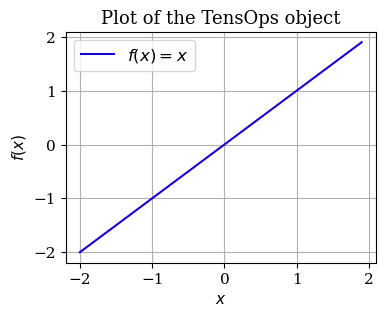

In [9]:
# Figure to plot
plt.figure()

plt.plot(xx1[0], f.values[0, 0, :], label='$f(x) = x$')

# Personalization of the plot
plt.title("Plot of the TensOps object")
plt.xlabel("$x$")
plt.ylabel("$f(x)$")

plt.grid()
plt.legend()

plt.tick_params(axis='both')
plt.rc('text', usetex=True)
plt.rc('font', family='serif')

# Show the plot
plt.show()

In [10]:
# f(x, y) = x + y

# We declarate the function symbolically and then we lambdify it to evaluate it in the grid.
x, y = sp.symbols('x y')
f_sym = x + y

# We transform it to a TensOps object
f_ = torch.tensor(np.array(sp.lambdify((x, y), f_sym, 'numpy')(xx2, yy2))).unsqueeze(0).unsqueeze(0)
f = TensOps(f_, domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None)

print(f)

<class 'TensOps'>
 Shape: [1, 1, 40, 40]

 Order: [0, 0]
 Domain dim: 2
 Codomain dim: [1]

 Base: None
 Contravariant indices: None
 Covariant indices: None


In [11]:
# Figure to plot
plt.figure()

plt.imshow(f.values[0, 0, :])
plt.colorbar()

# Personalization of the plot
plt.title("Plot of the TensOps object")
plt.xlabel("$x$")
plt.ylabel("$y$")

plt.tick_params(axis='both')
plt.rc('text', usetex=True)
plt.rc('font', family='serif')

# Show the plot
plt.show()

RuntimeError: Failed to process string with tex because latex could not be found

<Figure size 400x300 with 2 Axes>

In [12]:
# f(x, y, z) = x + y + z

# We declarate the function symbolically and then we lambdify it to evaluate it in the grid.
x, y, z = sp.symbols('x y z')
f_sym = x**2 + y**2 + z**2

# We create the tensor that will allocate the values of the function
f_ = torch.tensor(np.array(sp.lambdify((x, y, z), f_sym, 'numpy')(xx3, yy3, zz3))).unsqueeze(0).unsqueeze(0)
f = TensOps(f_, domain_dim=3, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None)

print(f)

<class 'TensOps'>
 Shape: [1, 1, 40, 40, 40]

 Order: [0, 0]
 Domain dim: 3
 Codomain dim: [1]

 Base: None
 Contravariant indices: None
 Covariant indices: None


In [13]:
# Figure to plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

sc = ax.scatter(xx3, yy3, zz3, c= f.values[0, 0, :, :, :], cmap='viridis', marker='o')
plt.colorbar(sc, shrink=0.55, location='bottom', pad = 0.15)

# Personalization of the plot
ax.set_title("Plot of the TensOps object")
ax.set_xlabel('$x$ axis')
ax.set_ylabel('$y$ axis')
ax.set_zlabel('$z$ axis')

scale = 1.2
w, h = fig.get_size_inches()
fig.set_size_inches(w * scale, h * scale)

# Show the plot
plt.tight_layout()
plt.show()

RuntimeError: Failed to process string with tex because latex could not be found

Error in callback <function _draw_all_if_interactive at 0x7f3e7fcaf880> (for post_execute), with arguments args (),kwargs {}:


RuntimeError: Failed to process string with tex because latex could not be found

RuntimeError: Failed to process string with tex because latex could not be found

<Figure size 480x360 with 2 Axes>

# Tensorial order $\mathcal{T}^1$

### **Vectorial fields**

In mathematics and physics, we often encounter **vector-valued functions**, which assign a vector of real numbers to each point in a space of dimension $m$.  
Formally, we define a function with codomain dimension 2 as:

$$
    f: \mathbb{R}^m \mapsto \mathbb{R}^2 \ \ \ \forall m=\{1, 2, 3\}
$$

The following table summarizes the relationship between the domain and codomain dimensions, the tensor order, and their corresponding ``PyTorch`` tensor shapes for several example scalar fields.

<div align="center">

| Application                       | Domain dim $m$    | Codomain dim $n$  |Tensor order $p$  | PyTorch shape                   |
|:--------------:                   |:----------------: |:----------------: |:----------------:|:----------------:               |
| $F(x) = (x, \ x^2)$               | 1                 | 2                 | 1                | $[N, \ 2, \ n]$                 |
| $F(x, y) = (x+y, \ y^2)$          | 2                 | 2                 | 1                | $[N, \ 2, \ n_x, \ n_y]$        |
| $F(x, y, z) = (x+z, \ y^2+z)$     | 3                 | 2                 | 1                | $[N, \ 2, \ n_x, \ n_y, \ n_z]$ |

</div>


In [ ]:
# f(x) = (x, x^2)

# We declarate the function symbolically and then we lambdify it to evaluate it in the grid.
x = sp.symbols('x')
f_sym1 = x 
f_sym2 = x**2 

f_lambda1 = sp.lambdify(x, f_sym1, 'numpy')
f_lambda2 = sp.lambdify(x, f_sym2, 'numpy')

# We create the tensor that will allocate the values of the function
f_ = np.zeros((1, 2, len(xx1[0])), dtype=np.float32)
f_[:, 0, :] = f_lambda1(xx1[0])
f_[:, 1, :] = f_lambda2(xx1[0])
f_ = torch.tensor(f_, dtype=torch.float32)

# We transform it to a TensOps object
f = TensOps(f_, domain_dim=1, codomain_dim=[2], order=[1, 0], contravariant_indices=[0], covariant_indices=None)
print(f)

In [ ]:
# f(x, y) = (x + y, y^2)

# We declarate the function symbolically and then we lambdify it to evaluate it in the grid.
x, y = sp.symbols('x y')
f_sym1 = x + y
f_sym2 = y**2 

f_lambda1 = sp.lambdify((x, y), f_sym1, 'numpy')
f_lambda2 = sp.lambdify((x, y), f_sym2, 'numpy')

# We create the tensor that will allocate the values of the function
f_ = np.zeros((N_data, 2, len(xx2), len(yy2)), dtype=np.float32)
f_[:, 0, :] = f_lambda1(xx2, yy2)
f_[:, 1, :] = f_lambda2(xx2, yy2)
f_ = torch.tensor(f_, dtype=torch.float32)

# We transform it to a TensOps object
f = TensOps(f_, domain_dim=2, codomain_dim=[2], order=[1, 0], contravariant_indices=[0], covariant_indices=None)
print(f)

In [ ]:
# f(x, y, z) = (x + z, y^2 + z)

# We declarate the function symbolically and then we lambdify it to evaluate it in the grid.
x, y, z = sp.symbols('x y z')
f_sym1 = x + z
f_sym2 = y**2 + z

f_lambda1 = sp.lambdify((x, y, z), f_sym1, 'numpy')
f_lambda2 = sp.lambdify((x, y, z), f_sym2, 'numpy')

# We create the tensor that will allocate the values of the function
f_ = np.zeros((N_data, 2, len(xx3), len(yy3), len(zz3)), dtype=np.float32)
f_[:, 0, :] = f_lambda1(xx3, yy3, zz3)
f_[:, 1, :] = f_lambda2(xx3, yy3, zz3)
f_ = torch.tensor(f_, dtype=torch.float32)

# We transform it to a TensOps object
f = TensOps(f_, domain_dim=3, codomain_dim=[2], order=[1, 0], contravariant_indices=[0], covariant_indices=None)
print(f)

$$
    f: \mathbb{R}^m \to \mathbb{R}^3 \ \ \ \forall m=\{1, 2, 3\}
$$

<div align="center">

| Application                              | Domain dim $m$    | Codomain dim $n$  |Tensor order $p$  | PyTorch shape                   |
|:--------------:                          |:----------------: |:----------------: |:----------------:|:----------------:               |
| $F(x) = (x, \ x^2, \ x^3)$               | 1                 | 3                 | 1                | $[N, \ 3, \ n]$                 |
| $F(x, y) = (x+y, \ y^2, \ y^3)$          | 2                 | 3                 | 1                | $[N, \ 3, \ n_x, \ n_y]$        |
| $F(x, y, z) = (x+z, \ y^2+z, \ y^3+z)$   | 3                 | 3                 | 1                | $[N, \ 3, \ n_x, \ n_y, \ n_z]$ |

<div align="center">

In [ ]:
# f(x) = (x, x^2, x^3)

# We declarate the function symbolically and then we lambdify it to evaluate it in the grid.
x = sp.symbols('x')
f_sym1 = x 
f_sym2 = x**2 
f_sym3 = x**3 

f_lambda1 = sp.lambdify(x, f_sym1, 'numpy')
f_lambda2 = sp.lambdify(x, f_sym2, 'numpy')
f_lambda3 = sp.lambdify(x, f_sym3, 'numpy')

# We create the tensor that will allocate the values of the function
f_ = np.zeros((N_data, 3, len(xx1[0])), dtype=np.float32)
f_[:, 0, :] = f_lambda1(xx1[0])
f_[:, 1, :] = f_lambda2(xx1[0])
f_[:, 2, :] = f_lambda3(xx1[0])
f_ = torch.tensor(f_, dtype=torch.float32)

# We transform it to a TensOps object
f = TensOps(f_, domain_dim=1, codomain_dim=[3], order=[1, 0], contravariant_indices=[0], covariant_indices=None)
print(f)

In [ ]:
# f(x, y) = (x + y, y^2, y^3)

# We declarate the function symbolically and then we lambdify it to evaluate it in the grid.
x, y = sp.symbols('x y')
f_sym1 = x + y
f_sym2 = y**2 
f_sym3 = y**3 

f_lambda1 = sp.lambdify((x, y), f_sym1, 'numpy')
f_lambda2 = sp.lambdify((x, y), f_sym2, 'numpy')
f_lambda3 = sp.lambdify((x, y), f_sym3, 'numpy')

# We create the tensor that will allocate the values of the function
f_ = np.zeros((N_data, 3, len(xx2), len(yy2)), dtype=np.float32)
f_[:, 0, :] = f_lambda1(xx2, yy2)
f_[:, 1, :] = f_lambda2(xx2, yy2)
f_[:, 2, :] = f_lambda3(xx2, yy2)
f_ = torch.tensor(f_, dtype=torch.float32)

# We transform it to a TensOps object
f = TensOps(f_, domain_dim=2, codomain_dim=[3], order=[1, 0], contravariant_indices=[0], covariant_indices=None)
print(f)

In [ ]:
# f(x) = (x + z, y^2 + z, y^3 + z)

# We declarate the function symbolically and then we lambdify it to evaluate it in the grid.
x, y, z = sp.symbols('x y z')
f_sym1 = x + z
f_sym2 = y**2 + z
f_sym3 = y**3 + z

f_lambda1 = sp.lambdify((x, y, z), f_sym1, 'numpy')
f_lambda2 = sp.lambdify((x, y, z), f_sym2, 'numpy')
f_lambda3 = sp.lambdify((x, y, z), f_sym3, 'numpy')

# We create the tensor that will allocate the values of the function
f_ = np.zeros((N_data, 3, len(xx3), len(yy3), len(zz3)), dtype=np.float32)
f_[:, 0, :] = f_lambda1(xx3, yy3, zz3)
f_[:, 1, :] = f_lambda2(xx3, yy3, zz3)
f_[:, 2, :] = f_lambda3(xx3, yy3, zz3)
f_ = torch.tensor(f_, dtype=torch.float32)

# We transform it to a TensOps object
f = TensOps(f_, domain_dim=3, codomain_dim=[3], order=[1, 0], contravariant_indices=[0], covariant_indices=None)
print(f)

### Covariant vectors (one-forms)

Every vector above is **contravariant** (`order=[1, 0]`, base $V$). Its covariant
counterpart, a $(0, 1)$ tensor, is a **one-form** $\boldsymbol{\omega}=\omega_{i}\,
\mathbf{e}^{i}$ living in $V^{*}$. The canonical example is the **differential of a
scalar field**: for $\phi(x, y)$,

$$
\mathrm{d}\phi = \frac{\partial\phi}{\partial x}\,\mathrm{d}x
              + \frac{\partial\phi}{\partial y}\,\mathrm{d}y
$$

is a one-form, i.e. a covariant vector field. Taking
$\phi(x, y)=\tfrac{1}{2}(x^{2}+y^{2})$ gives $\mathrm{d}\phi = (x,\,y)$ *as covariant
components* $\omega_{i}$. Numerically its component array is identical to a
contravariant $(x, y)$, but the metadata declares it covariant — and `TensOps`
treats it accordingly (for instance, it refuses to add it to a contravariant
vector, since they live in different spaces).

In [ ]:
# One-form (covariant vector) w_i = d(phi), with phi(x, y) = (x^2 + y^2) / 2
x, y = sp.symbols('x y')
dphi_dx = sp.lambdify((x, y), sp.diff((x**2 + y**2) / 2, x), 'numpy')
dphi_dy = sp.lambdify((x, y), sp.diff((x**2 + y**2) / 2, y), 'numpy')

w_ = np.zeros((N_data, 2, len(xx2), len(yy2)), dtype=np.float32)
w_[:, 0] = dphi_dx(xx2, yy2) * np.ones_like(xx2)
w_[:, 1] = dphi_dy(xx2, yy2) * np.ones_like(xx2)

# order=[0, 1] together with a covariant index declares a one-form (base V*).
omega = TensOps(torch.tensor(w_), domain_dim=2, codomain_dim=[2], order=[0, 1], contravariant_indices=None, covariant_indices=[0])
print(omega)

# Tensor order $\mathcal{T}^2$

### **Second-Order Tensors → Matrices**

In general, a **second-order tensor** can be interpreted as a matrix. Formally, we can define a function that maps from a space of dimension $m$ to a matrix of size $k \times l$:

$$
f: \mathbb{R}^m \mapsto \mathbb{R}^{k \times l}, \quad \forall m \in \{1, 2, 3\}
$$

Second-order tensors can appear in different types depending on their index structure:  

- $\mathcal{T}^2_0$: contravariant, two upper indices  
- $\mathcal{T}^0_2$: covariant, two lower indices  
- $\mathcal{T}^1_1$: mixed, one upper and one lower index  

As an example, consider the following matrix-valued function of two variables:

$$
f(x, y) = \begin{bmatrix} x & y & x\\ y & x & y \end{bmatrix}
$$

This is a $2 \times 3$ matrix for each input $(x, y)$.

<div align="center">

| Application                     | Domain dim $m$  | Codomain dim $n$ | Tensor order $(r, s)$ | PyTorch shape                   |
|:--------------------------------:|:-----------------:|:------------------:|:------------------:|:----------------:               |
| $f(x, y) = \begin{bmatrix} x & y & x\\ y & x & y \end{bmatrix}$ | 2                 | $2 \times 3$      | (1, 1)                  | [N, 2, 3, $n_x$, $n_y$]       |

</div>


Although all three share the same $[k\times l]$ array, their index configuration
gives each a distinct geometric meaning:

- $\mathcal{T}^{2}_{0}$ (two upper indices, base $V\otimes V$): a bilinear form on
  the dual space, $V^{*}\times V^{*}\to\mathbb{R}$.
- $\mathcal{T}^{0}_{2}$ (two lower indices, base $V^{*}\otimes V^{*}$): a bilinear
  form on $V$, $V\times V\to\mathbb{R}$ — the **metric** $g_{ij}$ and any inner
  product are of this type.
- $\mathcal{T}^{1}_{1}$ (one upper, one lower, base $V\otimes V^{*}$): a **linear
  endomorphism** $V\to V$ — the type of the identity $\delta^{i}{}_{j}$ and of any
  change-of-basis or deformation operator.

Only the metadata distinguishes a bilinear form from a linear map; the raw numbers
are the same. Keeping that distinction is exactly what `TensOps` is for.

In [ ]:
# f(x, y) = [(x, y, x), (y, x, y)]

# We declarate the function symbolically and then we lambdify it to evaluate it in the grid.
x, y = sp.symbols('x y')
f_symx = x
f_symy = y

f_lambdax = sp.lambdify((x, y), f_symx, 'numpy')
f_lambday = sp.lambdify((x, y), f_symy, 'numpy')

# We create the tensor that will allocate the values of the function
f_ = np.zeros((N_data, 2, 3, len(xx2), len(yy2)), dtype=np.float32)
f_[:, 0, 0, :] = f_lambdax(xx2, yy2)
f_[:, 0, 1, :] = f_lambday(xx2, yy2)
f_[:, 0, 2, :] = f_lambdax(xx2, yy2)
f_[:, 1, 0, :] = f_lambday(xx2, yy2)
f_[:, 1, 1, :] = f_lambdax(xx2, yy2)
f_[:, 1, 2, :] = f_lambday(xx2, yy2)
f_ = torch.tensor(f_, dtype=torch.float32)

# We transform it to a TensOps object
f = TensOps(f_, domain_dim=2, codomain_dim=[2, 3], order=[1, 1], contravariant_indices=[0], covariant_indices=[1])
print(f)

### **Third-Order Tensors → Tensor Fields in $\mathbb{R}^{k \times l \times p}$**

A **third-order tensor** extends the concept of a matrix (a second-order tensor) by adding one more dimension.  
Formally, we can define a function that maps from a space of dimension $m$ to a tensor of size $k \times l \times p$:

$$
    f: \mathbb{R}^m \mapsto \mathbb{R}^{k \times l \times p}, \quad \forall m \in \{1, 2, 3\}
$$

Third-order tensors may represent spatially varying matrices, gradient tensors, or more complex multidimensional quantities that arise in continuum mechanics and deep learning.

Such tensors can be of different index types:

- $\mathcal{T}^3_0$: three contravariant indices  
- $\mathcal{T}^0_3$: three covariant indices  
- $\mathcal{T}^2_1$, $\mathcal{T}^1_2$: mixed index types  

As an illustrative example, consider the following third-order tensor-valued function of two variables:

$$
    f(x, y) =
        \begin{bmatrix}
            \begin{bmatrix} x & y \\ y & x \end{bmatrix},
            \begin{bmatrix} y & x \\ x & y \end{bmatrix},
            \begin{bmatrix} x+y & xy \\ y^2 & x^2 \end{bmatrix}
        \end{bmatrix}
$$

Each evaluation $f(x, y)$ produces a tensor of shape $2 \times 2 \times 3$.

<div align="center">

| Application | Domain dim $m$ | Codomain dim $n$ | Tensor order $(r, s)$ | PyTorch shape |
|:------------:|:---------------:|:----------------:|:----------------------:|:--------------:|
| $f(x, y) =$ $\begin{bmatrix}\begin{bmatrix}x & y\\y & x\end{bmatrix}, \begin{bmatrix}y & x\\x & y\end{bmatrix}, \begin{bmatrix}x+y & xy\\y^2 & x^2\end{bmatrix}\end{bmatrix}$ | 2 | $2 \times 2 \times 3$ | (1, 2) | $[N, 2, 2, 3, n_x, n_y]$ |

</div>

In [ ]:
# We declarate the function symbolically and then we lambdify it to evaluate it in the grid.
x, y = sp.symbols('x y')
f_components = {
    (0, 0, 0): x,  (0, 0, 1): y,  (0, 0, 2): x,
    (0, 1, 0): y,  (0, 1, 1): x,  (0, 1, 2): y,
    (1, 0, 0): y,  (1, 0, 1): x,  (1, 0, 2): y,
    (1, 1, 0): x,  (1, 1, 1): y,  (1, 1, 2): x
}

# We create the tensor that will allocate the values of the function
f_lambdas = {k: sp.lambdify((x, y), expr, 'numpy') for k, expr in f_components.items()}
f_ = np.zeros((N_data, 2, 2, 3, len(xx2), len(yy2)), dtype=np.float32)
for (i, j, k), f_l in f_lambdas.items():
    f_[:, i, j, k, :, :] = f_l(xx2, yy2)

# We transform it to a TensOps object
f = TensOps(f_, domain_dim=2, codomain_dim=[2, 2, 3], order=[1, 2], contravariant_indices=[1], covariant_indices=[0, 2])
print(f)

# Operating with `TensOps` objects

The sections above are a *construction gallery*: they show how to wrap raw data
into `TensOps` objects of increasing tensorial order. The whole point of carrying
that metadata, however, is to **operate** on these objects while the library keeps
the mathematical bookkeeping consistent.

This part covers the two most fundamental building blocks:

1. **Arithmetic** — how `TensOps` objects add, subtract, scale and divide, and how
   the metadata (shape, base, order) is validated at every step.
2. **Geometric metadata** — how to declare the metric $g_{ij}$, its volume form
   $\sqrt{\det g}$ and an affine connection $\Gamma^k_{ij}$: the objects that turn
   a bare array of numbers into a field living on a (possibly curved) space.

## Arithmetic operations

`TensOps` overloads the usual Python arithmetic operators, but every one of them
enforces the tensor-algebra rules:

- **Addition / subtraction** (`+`, `-`) require *both operands to share the exact
  same shape and base* — you may only add tensors that live in the same space.
- **Scalar multiplication / division** (`*`, `/`) accept either a plain Python
  number or a `TensOps` **scalar field** (order `[0, 0]`). Multiplying a
  higher-order tensor by a scalar field broadcasts the scalar over every component
  while leaving the tensor's base untouched.
- **Unary negation** (`-T`) flips the sign of every component.

Let us build two scalar fields on the 2D grid and combine them.

In [ ]:
# Two scalar fields on the 2D grid: f(x, y) = x + y and h(x, y) = x * y
x, y = sp.symbols('x y')

f_ = np.array(sp.lambdify((x, y), x + y, 'numpy')(xx2, yy2), dtype=np.float32)
f = TensOps(torch.tensor(f_).unsqueeze(0).unsqueeze(0), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None)

h_ = np.array(sp.lambdify((x, y), x * y, 'numpy')(xx2, yy2), dtype=np.float32)
h = TensOps(torch.tensor(h_).unsqueeze(0).unsqueeze(0), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None)

# Element-wise addition and subtraction return new TensOps objects.
sum_field = f + h
diff_field = f - h

print(sum_field)

In [ ]:
# Visualize the two operands and their sum.
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))

for ax, field, title in zip(
    axes,
    [f, h, sum_field],
    ["$f = x + y$", "$h = x\\,y$", "$f + h$"],
):
    im = ax.imshow(field.values[0, 0].T, origin='lower', extent=[xr.min(), xr.max(), yr.min(), yr.max()])
    ax.set_title(title)
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    fig.colorbar(im, ax=ax, shrink=0.85)

plt.tight_layout()
plt.show()

In [ ]:
# Scalar scaling by a Python number, division and unary negation.
double_f = 2.0 * f     # left scalar multiplication (dispatches to __rmul__)
half_f = f / 2.0       # scalar division
neg_f = -f             # unary negation

# Multiplying / dividing by a TensOps *scalar field* is also allowed.
product = f * h        # scalar field times scalar field

for name, tensor in [("2 * f", double_f), ("f / 2", half_f), ("-f", neg_f), ("f * h", product)]:
    print(f"{name:8s} -> shape {tuple(tensor.values.shape)}, order {tensor.order}, base {tensor.base}")

### Scaling a vector field by a scalar field

Multiplication broadcasts a scalar field over every component of a higher-order
tensor **without touching its base**: the result is still a vector field, only
rescaled point by point. This is exactly what lets you write expressions such as
$\phi(x)\,\mathbf{u}(x)$ directly.

In [ ]:
# Vector field u(x, y) = (x, y) scaled by the scalar field f(x, y) = x + y
u_ = np.zeros((N_data, 2, len(xx2), len(yy2)), dtype=np.float32)
u_[:, 0] = xx2
u_[:, 1] = yy2
u = TensOps(torch.tensor(u_), domain_dim=2, codomain_dim=[2], order=[1, 0], contravariant_indices=[0], covariant_indices=None)

u_scaled = u * f   # (x + y) * (x, y), still a vector field

print("u     ->", "base", u.base, "| order", u.order, "| shape", tuple(u.values.shape))
print("u * f ->", "base", u_scaled.base, "| order", u_scaled.order, "| shape", tuple(u_scaled.values.shape))

### The metadata is enforced

Because every `TensOps` object knows its own base, operations that are not
mathematically well defined are rejected instead of silently producing garbage.
Adding a scalar field to a vector field, for instance, raises a `ValueError`.

In [ ]:
# You cannot add tensors that live in different spaces.
try:
    _ = f + u
except ValueError as error:
    print("f + u is rejected:")
    print(error)

## The metric, the volume form and the connection

Everything above works on a **flat** grid, where distances and volumes are the
plain Euclidean ones. To do tensor calculus on a general (possibly curved) space
we need three extra pieces of geometric metadata:

- the **metric** $g_{ij}$ — a symmetric, positive-definite rank-2 *covariant*
  tensor that measures lengths and angles;
- the **volume form** $\sqrt{\det g}$ — the scalar density that weights integrals
  over the domain;
- an **affine connection** $\Gamma^k_{ij}$ — the coefficients that tell derivatives
  how the basis twists from point to point.

`TensOps` ships one dedicated type for each: `MetrOps`, `VolFormOps` and
`ConnectOps`.

In [ ]:
# A connection is built from derivatives of the metric, so we first assemble a
# bank of finite-difference kernels matching the domain dimension (2D here).
D = Derivative(dx, dy, indexing='xy').two_dimensions()

### Declaring a metric — `MetrOps`

A metric is a rank-2 **fully covariant** tensor $g_{ij}$, so its order is fixed to
`[0, 2]` and you only supply the data, the domain dimension and the (square)
codomain `[d, d]`. On construction, `MetrOps` checks that the field is square,
symmetric and positive definite at every grid point.

The simplest metric is the Euclidean one, $g_{ij} = \delta_{ij}$ (the identity at
every point).

In [ ]:
# Euclidean metric g_ij = delta_ij, constant over the whole 2D grid.
G = list(xx2.shape)
euclid_ = torch.eye(2, dtype=torch.float32).reshape(1, 2, 2, 1, 1).expand(N_data, 2, 2, *G).clone()
euclid_metric = MetrOps(euclid_, domain_dim=2, codomain_dim=[2, 2])

print(euclid_metric)

### Deriving the volume form — `VolFormOps`

The volume form is $\sqrt{\det g}$, a **scalar field** (order `[0, 0]`). It is
built directly from a metric — you never assemble it by hand — and is meant to be
used as the weight in volume integrals, e.g. `integrand * volume_form`. For the
Euclidean metric it is identically 1.

In [ ]:
euclid_volume = VolFormOps(euclid_metric)
print(euclid_volume)
print("mean sqrt(det g) =", float(euclid_volume.values.mean()))

### A non-Euclidean metric

Nothing forces the metric to be constant or Euclidean. As a genuinely curved
example, take the diagonal metric

$$
g_{ij}(x, y) =
\begin{bmatrix} 1 + x^2 & 0 \\ 0 & 1 + y^2 \end{bmatrix},
$$

which is symmetric and positive definite everywhere. Its volume form is
$\sqrt{(1 + x^2)(1 + y^2)}$, growing away from the origin.

In [ ]:
# Diagonal, spatially varying metric g = diag(1 + x^2, 1 + y^2).
g_ = np.zeros((N_data, 2, 2, *G), dtype=np.float32)
g_[:, 0, 0] = 1 + xx2**2
g_[:, 1, 1] = 1 + yy2**2
metric = MetrOps(torch.tensor(g_), domain_dim=2, codomain_dim=[2, 2])

volume = VolFormOps(metric)
print(metric)
print(volume)

In [ ]:
# The volume form grows with the distance to the origin.
plt.figure()
plt.imshow(volume.values[0, 0].T, origin='lower', extent=[xr.min(), xr.max(), yr.min(), yr.max()])
plt.colorbar(label=r"$\sqrt{\det g}$")
plt.title("Volume form of the non-Euclidean metric")
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.show()

### Declaring a connection — `ConnectOps`

An affine connection $\Gamma^k_{ij}$ is **not a tensor** (under a change of
coordinates its coefficients pick up an inhomogeneous, second-derivative term), so
`ConnectOps` is a standalone type, independent from `TensOps`, that speaks of
*upper* and *lower* indices instead of the contra-/covariant vocabulary. Its
coefficients are stored with shape `[N, d, d, d, ...]`.

There are two ways to obtain one:

- **`ConnectOps.levi_civita(metric, D)`** — the factory that builds the unique
  torsion-free, metric-compatible connection (the Christoffel symbols) from a
  metric and the derivative bank `D`. It lives on a grid one node smaller per
  direction, because it differentiates the metric with finite differences.
- **`ConnectOps(data, domain_dim, codomain_dim)`** — the permissive raw container,
  for when you already have the coefficients (a flat connection, for instance, is
  simply all zeros).

In [ ]:
# Levi-Civita (Christoffel) connection of the non-Euclidean metric.
connection = ConnectOps.levi_civita(metric, D)
print(connection)

In [ ]:
# The permissive container: a flat connection is simply all-zero coefficients.
flat_ = torch.zeros((N_data, 2, 2, 2, *G), dtype=torch.float32)
flat_connection = ConnectOps(flat_, domain_dim=2, codomain_dim=[2, 2, 2])
print(flat_connection)